# Applied Machine Learning - Credit Card Default Prediction

**Dataset:** UCI *Default of Credit Card Clients* (dataset not used in Projects 1 and 2).

This notebook will prepare the data, compare two classifiers by cross-validation, tune the stronger one, and evaluate it once on a held-out test set.


## How this notebook is organised

1. **Setup**: imports and package versions.
2. **Dataset loading and inspection**: shape, head, columns, dtypes, data quality.


## Setup and reproducibility

- Fixed random seed (`RANDOM_STATE = 0`) for repeatable runs.
- `requirements.txt` is generated from this environment with `pip freeze`.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import (
    train_test_split, cross_val_score, GridSearchCV, TunedThresholdClassifierCV,
)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve,
    make_scorer,
)

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 30)

print("python", sys.version.split()[0])
print("numpy", np.__version__)
print("pandas", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib", matplotlib.__version__)

python 3.13.15
numpy 2.5.4
pandas 3.1.0
scikit-learn 1.9.1
matplotlib 3.11.2


## Dataset loading and inspection

- CSV loaded from disk; no network needed at run time.
- Shows shape, first rows, columns, and dtypes.


In [2]:
df = pd.read_csv("default_of_credit_card_clients.csv")
print("shape", df.shape)
df.head()

shape (30000, 24)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23,default
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
print("columns:", list(df.columns))
df.info()

columns: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'default']
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   X1       30000 non-null  int64
 1   X2       30000 non-null  int64
 2   X3       30000 non-null  int64
 3   X4       30000 non-null  int64
 4   X5       30000 non-null  int64
 5   X6       30000 non-null  int64
 6   X7       30000 non-null  int64
 7   X8       30000 non-null  int64
 8   X9       30000 non-null  int64
 9   X10      30000 non-null  int64
 10  X11      30000 non-null  int64
 11  X12      30000 non-null  int64
 12  X13      30000 non-null  int64
 13  X14      30000 non-null  int64
 14  X15      30000 non-null  int64
 15  X16      30000 non-null  int64
 16  X17      30000 non-null  int64
 17  X18      30000 non-null  int64
 18  X19 

**Data quality.**

- No missing values.
- 35 rows are exact duplicates (label included); kept, since identical attribute patterns can belong to different clients.
- 14 test rows have an exact twin in the training set.
- Target imbalanced: about 22% default; metrics below are chosen for imbalance.
- About 6% of clients have at least one negative bill-statement amount (credit balance, not debt).


missing values in the whole table: 0
duplicate rows: 35
default counts {0: 23364, 1: 6636}
default rate 0.2212


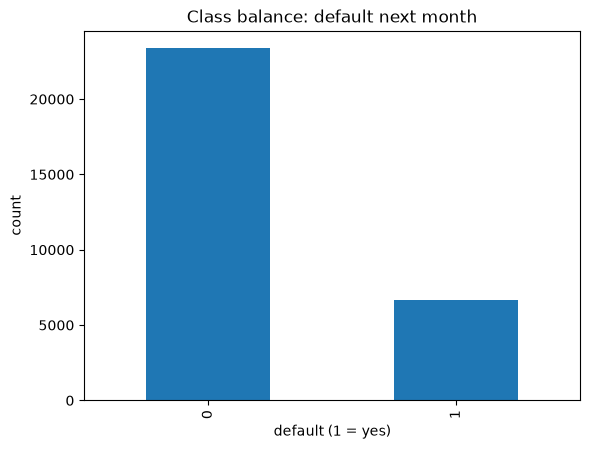

In [4]:
print("missing values in the whole table:", int(df.isnull().sum().sum()))
print("duplicate rows:", int(df.duplicated().sum()))
counts = df["default"].value_counts().sort_index()
print("default counts", counts.to_dict())
print("default rate", round(float(df["default"].mean()), 4))
df["default"].value_counts().sort_index().plot(kind="bar")
plt.title("Class balance: default next month")
plt.xlabel("default (1 = yes)")
plt.ylabel("count")
plt.show()